# A/B-тест SMS-коммуникации: от дизайна эксперимента до бизнес-решения

**Цель анализа:** проверить, увеличивает ли SMS-коммуникация вероятность покупки клиента, убедиться в корректности рандомизации и сформулировать границы бизнес-вывода.

**Единица рандомизации и анализа:** клиент (`client_id`).  
**Control:** `treatment_flg = 0`; **Treatment:** `treatment_flg = 1`.  
**Primary outcome:** `target = 1`, если клиент совершил покупку в период измерения результата.

Notebook выстроен последовательно: дизайн → проверка эксперимента → pre-treatment balance → основной эффект → исследовательская гетерогенность → решение.


## 0. Подготовка окружения

Импортируем библиотеки, задаём единый стиль графиков и пути. Путь определяется и при запуске из корня проекта, и при запуске из папки `notebooks`.


In [1]:
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy import stats
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize, proportions_ztest
import statsmodels.formula.api as smf

warnings.filterwarnings("ignore", category=FutureWarning)

# Находим корень проекта независимо от текущей рабочей директории.
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data" / "raw").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = PROJECT_ROOT / "data" / "raw"
PROCESSED_PATH = PROJECT_ROOT / "data" / "processed"
PROCESSED_PATH.mkdir(parents=True, exist_ok=True)

plt.style.use("seaborn-v0_8-whitegrid")
COLORS = {"Control": "#4C78A8", "Treatment": "#F58518"}
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda value: f"{value:,.4f}")


## 1. Дизайн эксперимента

### 1.1. Бизнес-гипотеза и метрики

**Гипотеза:** отправка SMS повышает вероятность покупки по сравнению с отсутствием SMS.

Метрики разделены по роли в решении. Primary metric отвечает на главный вопрос эксперимента. Secondary metrics помогают понять экономический механизм эффекта. Health/guardrail metrics защищают от нежелательных последствий.

В текущем датасете есть только бинарный post-treatment outcome `target`. Поэтому secondary и guardrail metrics ниже — это **требования к полноценному промышленному измерению**, а не фактически проверенные результаты этого анализа.


In [2]:
# Таблица фиксирует назначение метрик и доступность данных до просмотра результата.
metric_framework = pd.DataFrame(
    [
        ["Primary", "Purchase Conversion", "Доля клиентов с покупкой", "Да", "Главный критерий эффекта"],
        ["Secondary", "Revenue per user", "Выручка / рандомизированный клиент", "Нет", "Экономический масштаб эффекта"],
        ["Secondary", "Average order value", "Выручка / число заказов", "Нет", "Не компенсируется ли рост CR меньшим чеком"],
        ["Secondary", "Purchase frequency", "Число заказов / клиент", "Нет", "Изменение частоты покупок"],
        ["Guardrail", "Opt-out rate", "Доля отписок от коммуникаций", "Нет", "Допустимость давления на клиента"],
        ["Guardrail", "Complaint rate", "Доля клиентов с жалобой", "Нет", "Риск ухудшения клиентского опыта"],
        ["Guardrail", "Churn / retention", "Отток или удержание", "Нет", "Долгосрочный вред"],
        ["Guardrail", "Delivery / technical health", "Доставка SMS, ошибки", "Нет", "Корректность исполнения кампании"],
    ],
    columns=["Роль", "Метрика", "Определение", "Есть post-treatment данные", "Зачем нужна"],
)
display(metric_framework)


,Роль,Метрика,Определение,Есть post-treatment данные,Зачем нужна
0,Primary,Purchase Conversion,Доля клиентов с покупкой,Да,Главный критерий эффекта
1,Secondary,Revenue per user,Выручка / рандомизированный клиент,Нет,Экономический масштаб эффекта
2,Secondary,Average order value,Выручка / число заказов,Нет,Не компенсируется ли рост CR меньшим чеком
3,Secondary,Purchase frequency,Число заказов / клиент,Нет,Изменение частоты покупок
4,Guardrail,Opt-out rate,Доля отписок от коммуникаций,Нет,Допустимость давления на клиента
5,Guardrail,Complaint rate,Доля клиентов с жалобой,Нет,Риск ухудшения клиентского опыта
6,Guardrail,Churn / retention,Отток или удержание,Нет,Долгосрочный вред
7,Guardrail,Delivery / technical health,"Доставка SMS, ошибки",Нет,Корректность исполнения кампании


### 1.2. Статистические параметры, MDE, выборка и срок

Заранее фиксируем двусторонний тест, уровень значимости $\alpha=0.05$ и мощность $1-\beta=0.80$.

Логика планирования:

$$MDE \longrightarrow N_{required} \longrightarrow \text{доступный дневной трафик} \longrightarrow \text{срок теста}.$$

Чем меньше эффект хотим надёжно обнаружить, тем больше требуется выборка. Срок можно получить только как

$$\text{days}=\left\lceil\frac{N_{required,total}}{\text{eligible clients per day}}\right\rceil.$$

В данных нет даты попадания клиента в эксперимент и daily exposure, поэтому фактический срок теста **не вычисляем и не выдумываем**. Дополнительно в реальном запуске срок должен покрывать полный недельный цикл и быть зафиксирован заранее.


In [3]:
alpha = 0.05
power = 0.80
baseline_for_design = 0.60
allocation_ratio = 1.0
power_analysis = NormalIndPower()

# Показываем, как бизнес-значимый MDE превращается в требуемый размер выборки.
design_rows = []
for mde_pp in [0.6, 1.0, 2.0]:
    treatment_rate = baseline_for_design + mde_pp / 100
    effect_size = proportion_effectsize(treatment_rate, baseline_for_design)
    required_per_arm = power_analysis.solve_power(
        effect_size=effect_size,
        alpha=alpha,
        power=power,
        ratio=allocation_ratio,
        alternative="two-sided",
    )
    required_control = int(np.ceil(required_per_arm))
    required_treatment = int(np.ceil(required_per_arm * allocation_ratio))
    design_rows.append(
        {
            "MDE, п.п.": mde_pp,
            "Required N: Control": required_control,
            "Required N: Treatment": required_treatment,
            "Required N: total": required_control + required_treatment,
        }
    )

design_table = pd.DataFrame(design_rows)
display(design_table)


,"MDE, п.п.",Required N: Control,Required N: Treatment,Required N: total
0,0.6000,104385,104385,208770
1,1.0000,37513,37513,75026
2,2.0000,9335,9335,18670


**Интерпретация design table.** Для MDE 0.6 п.п. требуется около 200 тыс. клиентов суммарно. Перевести это число в календарные дни без дневного потока eligible-клиентов нельзя. В разделе результатов отдельно рассчитаем фактическую чувствительность при реально полученном размере групп.


## 2. Загрузка данных и контроль качества

Сначала загружаем эксперимент и клиентские признаки. До анализа эффекта проверяем размер, ключи, пропуски и допустимые значения — иначе ошибка данных может выглядеть как эффект treatment.


In [4]:
experiment = pd.read_csv(DATA_PATH / "uplift_train.csv", dtype={"client_id": "string"})
clients = pd.read_csv(DATA_PATH / "clients.csv", dtype={"client_id": "string"})

# Сводка позволяет быстро проверить гранулярность и уникальность ключей.
data_quality = pd.DataFrame(
    {
        "Строк": [len(experiment), len(clients)],
        "Столбцов": [experiment.shape[1], clients.shape[1]],
        "Уникальных client_id": [experiment["client_id"].nunique(), clients["client_id"].nunique()],
        "Полных дублей": [experiment.duplicated().sum(), clients.duplicated().sum()],
        "Дублей client_id": [experiment["client_id"].duplicated().sum(), clients["client_id"].duplicated().sum()],
    },
    index=["experiment", "clients"],
)
display(data_quality)


,Строк,Столбцов,Уникальных client_id,Полных дублей,Дублей client_id
experiment,200039,3,200039,0,0
clients,400162,5,400162,0,0


Далее проверяем пропуски в экспериментальных полях и допустимые значения бинарных переменных. Ожидаем только `0/1`; primary-анализ требует одной строки на клиента.


In [5]:
experiment_checks = pd.DataFrame(
    {
        "Пропуски": experiment.isna().sum(),
        "Число уникальных": experiment.nunique(dropna=True),
    }
)
display(experiment_checks)

binary_values = pd.DataFrame(
    {
        "Поле": ["treatment_flg", "target"],
        "Наблюдаемые значения": [
            sorted(experiment["treatment_flg"].dropna().unique().tolist()),
            sorted(experiment["target"].dropna().unique().tolist()),
        ],
    }
)
display(binary_values)

assert experiment["client_id"].is_unique, "В эксперименте client_id должен быть уникальным"
assert set(experiment["treatment_flg"].unique()) == {0, 1}
assert set(experiment["target"].unique()) == {0, 1}


,Пропуски,Число уникальных
client_id,0,200039
treatment_flg,0,2
target,0,2


,Поле,Наблюдаемые значения
0,treatment_flg,"[0, 1]"
1,target,"[0, 1]"


## 3. Проверка эксперимента до оценки эффекта

### 3.1. Распределение по группам и SRM

Sample Ratio Mismatch (SRM) проверяет, соответствует ли фактическое распределение заранее ожидаемому 50/50. Очень маленький p-value здесь мог бы указывать на проблему назначения или логирования. Это диагностический тест механизма распределения, а не тест бизнес-эффекта.


In [6]:
allocation = (
    experiment.groupby("treatment_flg")["client_id"]
    .count()
    .rename(index={0: "Control", 1: "Treatment"})
    .to_frame("n")
)
allocation["Доля"] = allocation["n"] / allocation["n"].sum()

observed = allocation["n"].to_numpy()
expected = np.repeat(observed.sum() / 2, 2)
srm_chi2, srm_pvalue = stats.chisquare(observed, expected)

display(allocation)
print(f"SRM chi-square = {srm_chi2:.4f}; p-value = {srm_pvalue:.4f}")


,n,Доля
treatment_flg,,
Control,100058,0.5002
Treatment,99981,0.4998


SRM chi-square = 0.0296; p-value = 0.8633


**Интерпретация SRM.** `p = 0.863` не даёт оснований отвергать ожидаемое распределение 50/50. Размеры групп практически одинаковы; признаков sample ratio mismatch нет.


### 3.2. Объединение с клиентскими признаками

Добавляем только pre-treatment характеристики. Проверяем покрытие merge: потеря клиентов или дубли при соединении нарушили бы сопоставимость групп.


In [7]:
experiment_clients = experiment.merge(
    clients,
    on="client_id",
    how="left",
    validate="one_to_one",
    indicator=True,
)

merge_quality = pd.DataFrame(
    {
        "Показатель": ["Строк до merge", "Строк после merge", "Не найдено в clients"],
        "Значение": [
            len(experiment),
            len(experiment_clients),
            int((experiment_clients["_merge"] != "both").sum()),
        ],
    }
)
display(merge_quality)
experiment_clients = experiment_clients.drop(columns="_merge")


,Показатель,Значение
0,Строк до merge,200039
1,Строк после merge,200039
2,Не найдено в clients,0


### 3.3. Баланс возраста

Сначала показываем качество исходного поля `age`. Некорректные значения не удаляются из primary A/B-анализа: primary outcome не зависит от наличия корректного возраста. Диапазон 14–100 используется только для анализа возраста и возрастной гетерогенности.


In [8]:
# Диагностика исходного возраста выявляет выбросы и долю валидных значений.
age_quality = experiment_clients["age"].describe(
    percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
).to_frame("age")
display(age_quality)

valid_age = experiment_clients["age"].between(14, 100)
age_validity = (
    experiment_clients.assign(valid_age=valid_age)
    .groupby("treatment_flg")["valid_age"]
    .agg(["count", "sum", "mean"])
    .rename(index={0: "Control", 1: "Treatment"})
    .rename(columns={"count": "n", "sum": "Валидный age, n", "mean": "Валидный age, доля"})
)
display(age_validity)


,age
count,"200,039.0000"
mean,46.4173
std,49.5325
min,"-7,491.0000"
1%,17.0000
5%,22.0000
25%,34.0000
50%,45.0000
75%,59.0000
95%,72.0000


,n,"Валидный age, n","Валидный age, доля"
treatment_flg,,,
Control,100058,99626,0.9957
Treatment,99981,99530,0.9955


Для непрерывного возраста сравниваем среднее, стандартное отклонение, медиану и квартильный диапазон. Главный balance diagnostic — standardized mean difference (SMD). Практический ориентир: `|SMD| < 0.1` означает хороший баланс.


In [9]:
def standardized_mean_difference(control: pd.Series, treatment: pd.Series) -> float:
    # SMD для непрерывного признака без использования размера выборки.
    control = control.dropna().astype(float)
    treatment = treatment.dropna().astype(float)
    pooled_sd = np.sqrt((control.var(ddof=1) + treatment.var(ddof=1)) / 2)
    if pooled_sd == 0:
        return 0.0
    return (treatment.mean() - control.mean()) / pooled_sd


age_analysis = experiment_clients.loc[valid_age].copy()
age_balance = (
    age_analysis.groupby("treatment_flg")["age"]
    .agg(n="count", mean="mean", std="std", median="median", q25=lambda x: x.quantile(0.25), q75=lambda x: x.quantile(0.75))
    .rename(index={0: "Control", 1: "Treatment"})
)
age_smd = standardized_mean_difference(
    age_analysis.loc[age_analysis["treatment_flg"] == 0, "age"],
    age_analysis.loc[age_analysis["treatment_flg"] == 1, "age"],
)
display(age_balance)
print(f"Age SMD = {age_smd:.4f}; |SMD| < 0.1: {abs(age_smd) < 0.1}")


,n,mean,std,median,q25,q75
treatment_flg,,,,,,
Control,99626,46.3781,15.8535,45.0000,34.0000,59.0000
Treatment,99530,46.4645,15.8970,45.0000,34.0000,59.0000


Age SMD = 0.0054; |SMD| < 0.1: True


### 3.4. Баланс пола

Для категориального признака сравниваем доли каждой категории и считаем SMD для соответствующего бинарного индикатора. Так виден и размер различия, и его практическая значимость; p-value для balance не используется как основной критерий.


In [10]:
def binary_smd(control_share: float, treatment_share: float) -> float:
    # SMD для разницы двух долей.
    pooled_share = (control_share + treatment_share) / 2
    denominator = np.sqrt(pooled_share * (1 - pooled_share))
    return 0.0 if denominator == 0 else (treatment_share - control_share) / denominator


gender_shares = pd.crosstab(
    experiment_clients["gender"].fillna("Missing"),
    experiment_clients["treatment_flg"],
    normalize="columns",
).rename(columns={0: "Control", 1: "Treatment"})
gender_shares["SMD"] = [
    binary_smd(row["Control"], row["Treatment"])
    for _, row in gender_shares.iterrows()
]
gender_shares["|SMD| < 0.1"] = gender_shares["SMD"].abs() < 0.1
display(gender_shares)


treatment_flg,Control,Treatment,SMD,|SMD| < 0.1
gender,,,,
F,0.3676,0.3692,0.0032,True
M,0.1678,0.1673,-0.0013,True
U,0.4646,0.4635,-0.0021,True


### 3.5. Behavioral pre-test balance из `purchases.csv`

Демографический баланс не гарантирует баланс исторического покупательского поведения. Поэтому строим признаки по периоду **до измерения результата**:

- число уникальных транзакций;
- historical spend;
- average check;
- recency относительно максимальной даты исторического периода;
- начисленные и списанные баллы.

`purchases.csv` имеет гранулярность товарной строки: одна транзакция занимает несколько строк, а `purchase_sum` и points повторяются. Файл читается чанками и сначала дедуплицируется до `(client_id, transaction_id)`. Целиком 4.2 GB в память не загружаются. Последняя транзакция чанка переносится в следующий чанк, чтобы граница чтения не создавала дубль.


In [11]:
PURCHASES_PATH = DATA_PATH / "purchases.csv"
FEATURES_CACHE = PROCESSED_PATH / "pretest_customer_features_v2.csv.gz"
CHUNK_SIZE = 750_000

purchase_columns = [
    "client_id",
    "transaction_id",
    "transaction_datetime",
    "regular_points_received",
    "express_points_received",
    "regular_points_spent",
    "express_points_spent",
    "purchase_sum",
]


def aggregate_transaction_rows(frame: pd.DataFrame) -> pd.DataFrame:
    # Переводит товарные строки в транзакции, затем в клиентские агрегаты.
    if frame.empty:
        return pd.DataFrame()

    # Суммы чека и баллы заданы на уровне транзакции и повторяются по товарам.
    transactions = frame.drop_duplicates(["client_id", "transaction_id"], keep="first").copy()
    numeric_columns = [
        "regular_points_received",
        "express_points_received",
        "regular_points_spent",
        "express_points_spent",
        "purchase_sum",
    ]
    transactions[numeric_columns] = transactions[numeric_columns].fillna(0)
    transactions["points_received"] = (
        transactions["regular_points_received"] + transactions["express_points_received"]
    )
    transactions["points_spent"] = (
        -(transactions["regular_points_spent"] + transactions["express_points_spent"])
    )

    return transactions.groupby("client_id", as_index=False).agg(
        transactions=("transaction_id", "nunique"),
        historical_spend=("purchase_sum", "sum"),
        last_purchase=("transaction_datetime", "max"),
        points_received=("points_received", "sum"),
        points_spent=("points_spent", "sum"),
    )


def build_pretest_features(path: Path, experiment_ids: set[str]) -> tuple[pd.DataFrame, str, int]:
    # Потоково агрегирует большой line-item файл без загрузки целиком.
    partial_aggregates = []
    carry = pd.DataFrame()
    reference_datetime = None
    rows_read = 0

    reader = pd.read_csv(
        path,
        usecols=purchase_columns,
        dtype={"client_id": "string", "transaction_id": "string"},
        chunksize=CHUNK_SIZE,
    )

    for chunk_number, raw_chunk in enumerate(reader, start=1):
        rows_read += len(raw_chunk)
        chunk_max = raw_chunk["transaction_datetime"].max()
        reference_datetime = max(reference_datetime, chunk_max) if reference_datetime else chunk_max

        if not carry.empty:
            raw_chunk = pd.concat([carry, raw_chunk], ignore_index=True)

        # Транзакции в исходном файле идут последовательными строками.
        last_client = raw_chunk.iloc[-1]["client_id"]
        last_transaction = raw_chunk.iloc[-1]["transaction_id"]
        is_last_transaction = (
            raw_chunk["client_id"].eq(last_client)
            & raw_chunk["transaction_id"].eq(last_transaction)
        )
        carry = raw_chunk.loc[is_last_transaction].copy()
        ready = raw_chunk.loc[~is_last_transaction]

        ready = ready.loc[ready["client_id"].isin(experiment_ids)]
        aggregated = aggregate_transaction_rows(ready)
        if not aggregated.empty:
            partial_aggregates.append(aggregated)

        if chunk_number % 10 == 0:
            print(f"Обработано чанков: {chunk_number}; строк: {rows_read:,}")

    carry = carry.loc[carry["client_id"].isin(experiment_ids)]
    final_aggregate = aggregate_transaction_rows(carry)
    if not final_aggregate.empty:
        partial_aggregates.append(final_aggregate)

    combined = pd.concat(partial_aggregates, ignore_index=True)
    features = combined.groupby("client_id", as_index=False).agg(
        transactions=("transactions", "sum"),
        historical_spend=("historical_spend", "sum"),
        last_purchase=("last_purchase", "max"),
        points_received=("points_received", "sum"),
        points_spent=("points_spent", "sum"),
    )
    features["average_check"] = features["historical_spend"] / features["transactions"]
    features["last_purchase"] = pd.to_datetime(features["last_purchase"])
    features["recency_days"] = (
        pd.Timestamp(reference_datetime) - features["last_purchase"]
    ).dt.total_seconds() / 86_400

    return features, reference_datetime, rows_read


if FEATURES_CACHE.exists():
    pretest_features = pd.read_csv(
        FEATURES_CACHE,
        dtype={"client_id": "string"},
        parse_dates=["last_purchase"],
    )
    reference_datetime = None
    rows_read = None
    print(f"Загружен кэш признаков: {FEATURES_CACHE.relative_to(PROJECT_ROOT)}")
else:
    pretest_features, reference_datetime, rows_read = build_pretest_features(
        PURCHASES_PATH,
        set(experiment["client_id"]),
    )
    # Кэш лежит внутри data/ и исключён из Git.
    pretest_features.to_csv(FEATURES_CACHE, index=False, compression="gzip")
    print(f"Создан кэш признаков: {FEATURES_CACHE.relative_to(PROJECT_ROOT)}")

print(f"Клиентов с историей покупок: {len(pretest_features):,}")
if reference_datetime is not None:
    print(f"Опорная дата recency (максимум pre-period): {reference_datetime}")
if rows_read is not None:
    print(f"Прочитано товарных строк: {rows_read:,}")


Обработано чанков: 10; строк: 7,500,000


Обработано чанков: 20; строк: 15,000,000


Обработано чанков: 30; строк: 22,500,000


Обработано чанков: 40; строк: 30,000,000


Обработано чанков: 50; строк: 37,500,000


Обработано чанков: 60; строк: 45,000,000


Создан кэш признаков: data/processed/pretest_customer_features_v2.csv.gz
Клиентов с историей покупок: 200,039
Опорная дата recency (максимум pre-period): 2019-03-18 23:40:03
Прочитано товарных строк: 45,786,568


Проверяем покрытие историей и объединяем признаки с экспериментом. Для клиентов без транзакций счётчики и суммы были бы равны нулю, а recency остался бы пропуском; отдельно показываем фактическую долю покрытия.


In [12]:
experiment_pretest = experiment.merge(
    pretest_features,
    on="client_id",
    how="left",
    validate="one_to_one",
    indicator=True,
)

pretest_coverage = (
    experiment_pretest.assign(has_history=experiment_pretest["_merge"].eq("both"))
    .groupby("treatment_flg")["has_history"]
    .agg(["count", "sum", "mean"])
    .rename(index={0: "Control", 1: "Treatment"})
    .rename(columns={"count": "n", "sum": "С историей, n", "mean": "Покрытие"})
)
display(pretest_coverage)

zero_fill = ["transactions", "historical_spend", "points_received", "points_spent"]
experiment_pretest[zero_fill] = experiment_pretest[zero_fill].fillna(0)
experiment_pretest["average_check"] = experiment_pretest["average_check"].fillna(0)
experiment_pretest = experiment_pretest.drop(columns="_merge")


,n,"С историей, n",Покрытие
treatment_flg,,,
Control,100058,100058,1.0000
Treatment,99981,99981,1.0000


Ниже для каждого behavioral-признака сопоставляем среднее, стандартное отклонение, медиану, 25-й и 75-й процентили. Raw SMD сохраняет исходную бизнес-шкалу; `log1p SMD` устойчивее к сильной правой асимметрии денежных и частотных признаков. Баланс оцениваем прежде всего по абсолютному SMD, а не по p-value.


In [13]:
behavioral_features = [
    "transactions",
    "historical_spend",
    "average_check",
    "recency_days",
    "points_received",
    "points_spent",
]

behavior_rows = []
for feature in behavioral_features:
    control = experiment_pretest.loc[experiment_pretest["treatment_flg"] == 0, feature]
    treatment = experiment_pretest.loc[experiment_pretest["treatment_flg"] == 1, feature]
    nonnegative_control = control.clip(lower=0)
    nonnegative_treatment = treatment.clip(lower=0)
    behavior_rows.append(
        {
            "Признак": feature,
            "Control mean": control.mean(),
            "Treatment mean": treatment.mean(),
            "Control median": control.median(),
            "Treatment median": treatment.median(),
            "Control q25": control.quantile(0.25),
            "Treatment q25": treatment.quantile(0.25),
            "Control q75": control.quantile(0.75),
            "Treatment q75": treatment.quantile(0.75),
            "Raw SMD": standardized_mean_difference(control, treatment),
            "log1p SMD": standardized_mean_difference(
                np.log1p(nonnegative_control), np.log1p(nonnegative_treatment)
            ),
        }
    )

behavior_balance = pd.DataFrame(behavior_rows).set_index("Признак")
behavior_balance["max |SMD| < 0.1"] = (
    behavior_balance[["Raw SMD", "log1p SMD"]].abs().max(axis=1) < 0.1
)
display(behavior_balance)


,Control mean,Treatment mean,Control median,Treatment median,Control q25,Treatment q25,Control q75,Treatment q75,Raw SMD,log1p SMD,max |SMD| < 0.1
Признак,,,,,,,,,,,
transactions,20.0561,20.1856,15.0000,15.0000,8.0000,8.0000,27.0000,27.0000,0.0073,0.0082,True
historical_spend,"8,569.3661","8,625.6995","6,070.1050","6,135.4400","3,129.0000","3,167.0000","11,067.7650","11,123.7500",0.0063,0.0095,True
average_check,494.7630,496.8042,393.8566,394.0969,261.1358,261.4683,607.7483,609.5650,0.0054,0.0032,True
recency_days,6.3014,6.3004,4.4058,4.4132,1.5547,1.5520,9.5819,9.5701,-0.0002,-0.0013,True
points_received,78.6091,79.0303,49.5000,49.6000,23.4000,23.5000,97.6000,98.3000,0.0042,0.0073,True
points_spent,79.7263,79.9766,39.0000,39.0000,0.0000,0.0000,109.0000,110.0000,0.0019,0.0057,True


График SMD сводит все pre-treatment проверки на одну шкалу. Точки между вертикальными границами −0.1 и +0.1 означают практически приемлемый баланс. Возраст и категории пола добавлены рядом с behavioral-признаками.


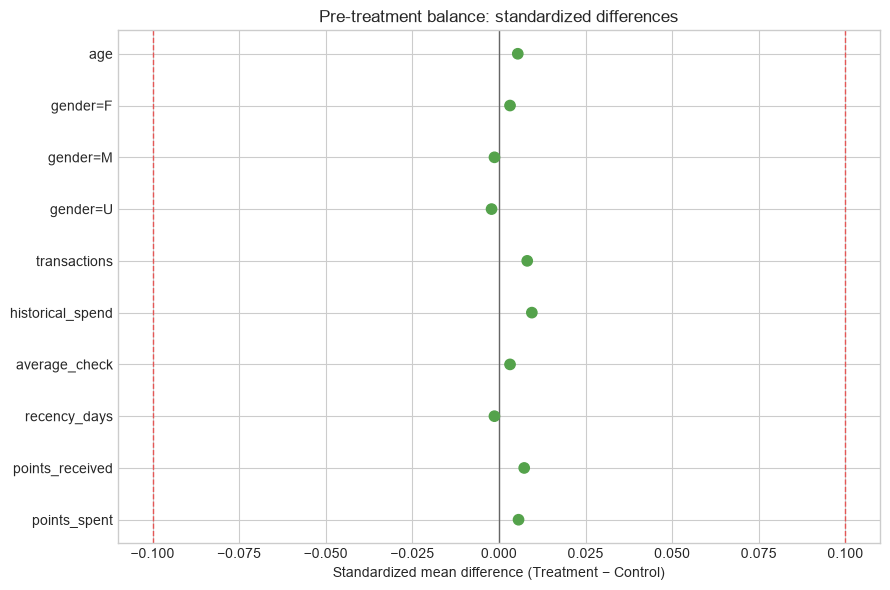

In [14]:
smd_for_plot = pd.Series(
    {"age": age_smd, **{f"gender={idx}": row["SMD"] for idx, row in gender_shares.iterrows()}},
    dtype=float,
)
smd_for_plot = pd.concat([smd_for_plot, behavior_balance["log1p SMD"]])

fig, ax = plt.subplots(figsize=(9, 6))
y_positions = np.arange(len(smd_for_plot))
point_colors = np.where(smd_for_plot.abs() < 0.1, "#54A24B", "#E45756")
ax.scatter(smd_for_plot.values, y_positions, color=point_colors, s=55, zorder=3)
ax.axvline(0, color="#666666", linewidth=1)
ax.axvline(-0.1, color="#E45756", linestyle="--", linewidth=1)
ax.axvline(0.1, color="#E45756", linestyle="--", linewidth=1)
ax.set_yticks(y_positions, smd_for_plot.index)
ax.set_xlabel("Standardized mean difference (Treatment − Control)")
ax.set_title("Pre-treatment balance: standardized differences")
ax.invert_yaxis()
plt.tight_layout()
plt.show()


**Вывод по валидации.** SRM отсутствует, а демографические и исторические поведенческие признаки должны иметь `|SMD|` существенно ниже 0.1. Это поддерживает корректность рандомизации по наблюдаемым pre-treatment характеристикам, хотя не может доказать отсутствие проблем по ненаблюдаемым признакам.


## 4. Основной результат A/B-теста

### 4.1. Purchase Conversion и uplift

Считаем conversion на исходной полной экспериментальной выборке — возрастные выбросы здесь не исключаются. Абсолютный uplift выражаем в процентных пунктах, относительный — относительно Control.


In [15]:
conversion = (
    experiment.groupby("treatment_flg")["target"]
    .agg(n="count", purchases="sum", conversion="mean")
    .rename(index={0: "Control", 1: "Treatment"})
)

control_cr = conversion.loc["Control", "conversion"]
treatment_cr = conversion.loc["Treatment", "conversion"]
n_control = int(conversion.loc["Control", "n"])
n_treatment = int(conversion.loc["Treatment", "n"])
absolute_uplift = treatment_cr - control_cr
relative_uplift = absolute_uplift / control_cr

conversion_display = conversion.copy()
conversion_display["conversion"] = conversion_display["conversion"].map(lambda x: f"{x:.3%}")
display(conversion_display)
print(f"Absolute uplift = {absolute_uplift * 100:.3f} п.п.")
print(f"Relative uplift = {relative_uplift:.3%}")


,n,purchases,conversion
treatment_flg,,,
Control,100058,60363,60.328%
Treatment,99981,63639,63.651%


Absolute uplift = 3.323 п.п.
Relative uplift = 5.508%


### 4.2. Статистическая неопределённость

Для разницы двух долей используем двусторонний z-test и 95% confidence interval. p-value отвечает на вопрос о совместимости данных с нулевым эффектом, а интервал показывает диапазон правдоподобных величин эффекта и важнее для бизнес-интерпретации.


In [16]:
successes = np.array([
    conversion.loc["Treatment", "purchases"],
    conversion.loc["Control", "purchases"],
])
observations = np.array([n_treatment, n_control])
z_stat, primary_pvalue = proportions_ztest(successes, observations, alternative="two-sided")

standard_error = np.sqrt(
    treatment_cr * (1 - treatment_cr) / n_treatment
    + control_cr * (1 - control_cr) / n_control
)
ci_low = absolute_uplift - stats.norm.ppf(1 - alpha / 2) * standard_error
ci_high = absolute_uplift + stats.norm.ppf(1 - alpha / 2) * standard_error

primary_result = pd.DataFrame(
    {
        "Control CR": [f"{control_cr:.3%}"],
        "Treatment CR": [f"{treatment_cr:.3%}"],
        "Absolute uplift": [f"{absolute_uplift * 100:.3f} п.п."],
        "Relative uplift": [f"{relative_uplift:.3%}"],
        "95% CI": [f"[{ci_low * 100:.3f}; {ci_high * 100:.3f}] п.п."],
        "z-stat": [z_stat],
        "p-value": [f"{primary_pvalue:.2e}"],
    }
)
display(primary_result)


,Control CR,Treatment CR,Absolute uplift,Relative uplift,95% CI,z-stat,p-value
0,60.328%,63.651%,3.323 п.п.,5.508%,[2.898; 3.748] п.п.,15.3093,6.62e-53


График показывает conversion и 95% CI для каждой группы. Это визуализация уровня метрики; формальный confidence interval эффекта приведён в таблице выше.


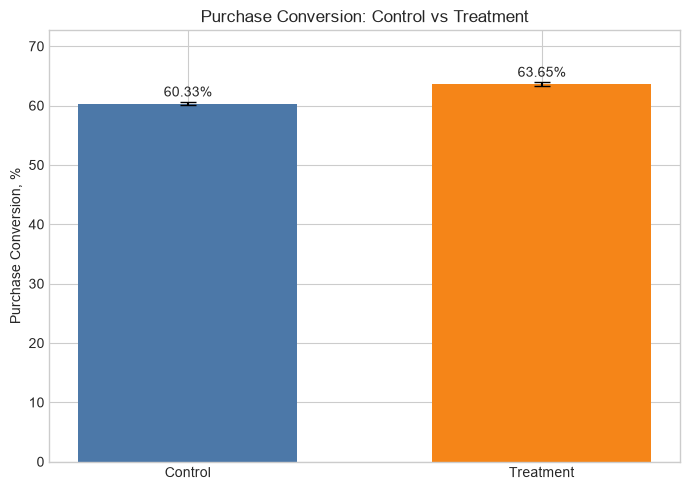

In [17]:
group_rates = conversion["conversion"] * 100
group_errors = np.array([
    1.96 * np.sqrt(control_cr * (1 - control_cr) / n_control) * 100,
    1.96 * np.sqrt(treatment_cr * (1 - treatment_cr) / n_treatment) * 100,
])

fig, ax = plt.subplots(figsize=(7, 5))
bars = ax.bar(
    group_rates.index,
    group_rates.values,
    yerr=group_errors,
    capsize=6,
    color=[COLORS["Control"], COLORS["Treatment"]],
    width=0.62,
)
ax.set_ylabel("Purchase Conversion, %")
ax.set_title("Purchase Conversion: Control vs Treatment")
ax.set_ylim(0, max(group_rates) + 9)
for bar, value in zip(bars, group_rates.values):
    ax.text(bar.get_x() + bar.get_width() / 2, value + 1.2, f"{value:.2f}%", ha="center")
plt.tight_layout()
plt.show()


### 4.3. Фактическая чувствительность и сравнение с MDE

При фактических размерах групп вычисляем минимальный различимый эффект около baseline 60%. Наблюдаемый uplift значительно больше чувствительности теста, поэтому результат не только статистически значим, но и уверенно превышает MDE ≈ 0.6 п.п.


In [18]:
actual_ratio = n_treatment / n_control
detectable_h = power_analysis.solve_power(
    effect_size=None,
    nobs1=n_control,
    alpha=alpha,
    power=power,
    ratio=actual_ratio,
    alternative="two-sided",
)
detectable_treatment_rate = np.sin(
    np.arcsin(np.sqrt(baseline_for_design)) + detectable_h / 2
) ** 2
sensitivity_mde = detectable_treatment_rate - baseline_for_design

sensitivity_table = pd.DataFrame(
    {
        "Параметр": ["Actual N Control", "Actual N Treatment", "Sensitivity MDE", "Observed uplift"],
        "Значение": [
            f"{n_control:,}",
            f"{n_treatment:,}",
            f"{sensitivity_mde * 100:.3f} п.п.",
            f"{absolute_uplift * 100:.3f} п.п.",
        ],
    }
)
display(sensitivity_table)


,Параметр,Значение
0,Actual N Control,"100,058"
1,Actual N Treatment,"99,981"
2,Sensitivity MDE,0.613 п.п.
3,Observed uplift,3.323 п.п.


## 5. Исследовательская гетерогенность по возрасту

Сегментный анализ выполняется только на клиентах с возрастом 14–100 и **не меняет** primary-результат. Группы возраста и interaction-анализ являются exploratory/post-hoc: они генерируют гипотезу для отдельного подтверждающего эксперимента, а не готовое правило таргетинга.


In [19]:
age_analysis["age_group"] = pd.cut(
    age_analysis["age"],
    bins=[14, 30, 45, 60, 100],
    labels=["14–30", "31–45", "46–60", "61–100"],
    include_lowest=True,
)

age_conversion = (
    age_analysis.groupby(["age_group", "treatment_flg"], observed=True)["target"]
    .agg(["count", "mean"])
    .reset_index()
)
age_rates = age_conversion.pivot(index="age_group", columns="treatment_flg", values="mean")
age_counts = age_conversion.pivot(index="age_group", columns="treatment_flg", values="count")
age_results = pd.DataFrame(
    {
        "Control n": age_counts[0].astype(int),
        "Treatment n": age_counts[1].astype(int),
        "Control CR": age_rates[0],
        "Treatment CR": age_rates[1],
        "Uplift, п.п.": (age_rates[1] - age_rates[0]) * 100,
    }
)
display(age_results)


,Control n,Treatment n,Control CR,Treatment CR,"Uplift, п.п."
age_group,,,,,
14–30,17781,17754,0.5803,0.5944,1.4063
31–45,32639,32218,0.5921,0.6193,2.7198
46–60,26852,27164,0.6053,0.6399,3.4573
61–100,22354,22394,0.6371,0.6921,5.5082


Визуализация показывает монотонное увеличение наблюдаемого absolute uplift с возрастом. Это описательный post-hoc паттерн; без отдельной валидации он может быть нестабилен и не доказывает, что следует ограничить рассылку старшими сегментами.


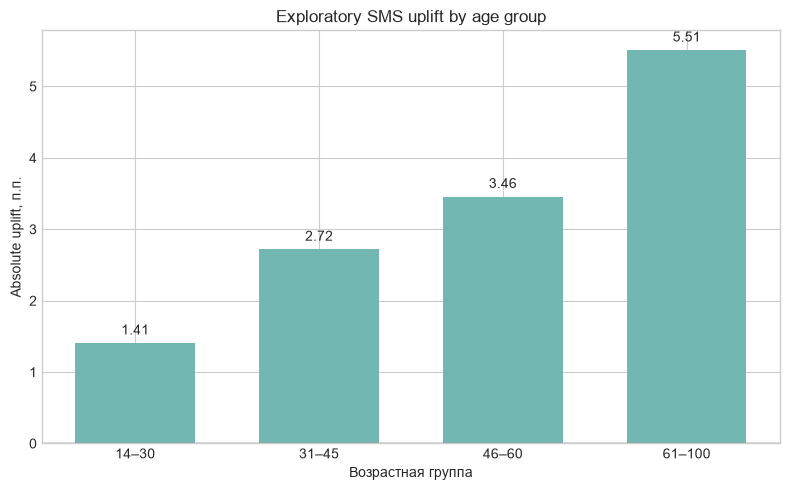

In [20]:
fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(
    age_results.index.astype(str),
    age_results["Uplift, п.п."],
    color="#72B7B2",
    width=0.65,
)
ax.axhline(0, color="#666666", linewidth=1)
ax.set_xlabel("Возрастная группа")
ax.set_ylabel("Absolute uplift, п.п.")
ax.set_title("Exploratory SMS uplift by age group")
for bar, value in zip(bars, age_results["Uplift, п.п."]):
    ax.text(bar.get_x() + bar.get_width() / 2, value + 0.12, f"{value:.2f}", ha="center")
plt.tight_layout()
plt.show()


### 5.1. Logistic interaction и likelihood-ratio test

Сравниваем логистическую модель с общим treatment-эффектом и модель с `treatment × age_group`. Likelihood-ratio test проверяет, улучшает ли набор interaction-термов описание данных. Важно: interaction тестируется на **log-odds scale**, поэтому LR test и простые различия conversion по сегментам отвечают на близкие, но не идентичные вопросы.


In [21]:
no_interaction_model = smf.logit(
    "target ~ treatment_flg + C(age_group)",
    data=age_analysis,
).fit(disp=False)
interaction_model = smf.logit(
    "target ~ treatment_flg * C(age_group)",
    data=age_analysis,
).fit(disp=False)

lr_stat = 2 * (interaction_model.llf - no_interaction_model.llf)
lr_df = int(interaction_model.df_model - no_interaction_model.df_model)
lr_pvalue = stats.chi2.sf(lr_stat, lr_df)

interaction_result = pd.DataFrame(
    {
        "LR statistic": [lr_stat],
        "df": [lr_df],
        "p-value": [f"{lr_pvalue:.2e}"],
        "Шкала": ["log-odds"],
        "Статус": ["exploratory / post-hoc"],
    }
)
display(interaction_result)


,LR statistic,df,p-value,Шкала,Статус
0,45.9691,3,5.76e-10,log-odds,exploratory / post-hoc


**Интерпретация interaction.** `LR = 45.9691`, `df = 3`, p-value очень мал: данные согласуются с неодинаковым treatment-эффектом между возрастными группами на log-odds scale. Из-за post-hoc природы анализа это основание для новой гипотезы, а не для немедленного age targeting.


## 6. Решение и бизнес-выводы

Итоговая таблица разделяет то, что установлено данными, и то, что пока не проверено. Это не позволяет статистической значимости автоматически превратиться в рекомендацию полного rollout.


In [22]:
decision_table = pd.DataFrame(
    [
        ["Primary effect", "Пройден", f"+{absolute_uplift * 100:.2f} п.п.; 95% CI [{ci_low * 100:.2f}; {ci_high * 100:.2f}]"],
        ["SRM / allocation", "Пройден", f"50/50; SRM p={srm_pvalue:.3f}"],
        ["Observed pre-treatment balance", "Пройден", "Демография и behavioral SMD ниже практического порога"],
        ["Post-treatment economics", "Не проверен", "Нет revenue, cost, AOV и frequency после treatment"],
        ["Guardrails", "Не проверены", "Нет opt-out, complaints, churn и delivery metrics"],
        ["Age targeting", "Требует валидации", "Exploratory interaction; нужен отдельный confirmatory test"],
    ],
    columns=["Блок решения", "Статус", "Основание"],
)
display(decision_table)


,Блок решения,Статус,Основание
0,Primary effect,Пройден,+3.32 п.п.; 95% CI [2.90; 3.75]
1,SRM / allocation,Пройден,50/50; SRM p=0.863
2,Observed pre-treatment balance,Пройден,Демография и behavioral SMD ниже практического...
3,Post-treatment economics,Не проверен,"Нет revenue, cost, AOV и frequency после treat..."
4,Guardrails,Не проверены,"Нет opt-out, complaints, churn и delivery metrics"
5,Age targeting,Требует валидации,Exploratory interaction; нужен отдельный confi...


### Финальный вывод

1. **SMS увеличивает Purchase Conversion.** Control CR ≈ **60.328%**, Treatment CR ≈ **63.651%**; absolute uplift ≈ **+3.32 п.п.**, relative uplift ≈ **+5.51%**. Двусторонний z-test даёт очень малый p-value, а 95% CI разницы — примерно **[2.90; 3.75] п.п.**
2. **Эксперимент выглядит технически корректным по доступным данным.** SRM отсутствует; распределения возраста, пола и исторического покупательского поведения сопоставимы по SMD.
3. **Наблюдаемый эффект существенно больше sensitivity MDE ≈ 0.6 п.п.** Теста достаточно для обнаружения эффекта такого масштаба.
4. **Полный rollout пока нельзя обосновать прибыльностью.** В датасете отсутствуют post-treatment revenue/AOV/frequency, стоимость SMS и guardrails. Следующий шаг — связать эксперимент с экономикой и клиентскими рисками, затем оценить incremental profit и заранее задать пороги допустимого ухудшения.
5. **Age heterogeneity — исследовательский результат.** Uplift возрастает от ≈ **1.41 п.п.** в группе 14–30 до ≈ **5.51 п.п.** в группе 61–100; LR test interaction значим, но проверяется на log-odds scale и требует отдельной confirmatory validation перед age targeting.

**Рекомендация:** считать гипотезу о росте conversion подтверждённой; перед широким запуском провести экономическую оценку и guardrail-проверку. Если бизнес хочет таргетировать по возрасту, заранее спроектировать отдельный эксперимент с фиксированными сегментами и correction/иерархической стратегией множественных сравнений.


## 7. Ограничения анализа

- Нет daily exposure и timestamp назначения в эксперимент: календарную длительность восстановить нельзя.
- Нет post-treatment транзакций, стоимости SMS и маржинальности: нельзя оценить incremental profit.
- Нет post-treatment guardrails: нельзя исключить рост отписок, жалоб или оттока.
- Behavioral balance подтверждает рандомизацию только по наблюдаемым историческим признакам.
- Возраст очищается до 14–100 только для age analysis; primary A/B использует всех рандомизированных клиентов.
- Сегментный анализ возраста post-hoc и не является готовой политикой таргетинга.
